# 03 · Taxonomía de clases, probabilidades y posiciones secundarias

El notebook 02 mostró que Fisher + KNN y KNN sin proyección empatan (~0.86), y que los errores se concentran en posiciones de banda (LW, RW, RM, LM) cuya etiqueta es más una convención que un perfil distinto.

Aquí se comprueban cuatro cosas:

1. **Taxonomía B:** crear una clase `Banda` (LM, RM, LW, RW) ¿resuelve la confusión?
2. **Techo de los datos:** un Random Forest como referencia. Si no supera mucho a KNN, el límite está en las etiquetas y no en el modelo.
3. **Salida probabilística:** ¿las probabilidades de KNN son informativas y están calibradas? Se evalúa con top-2 y log-loss.
4. **Posiciones secundarias:** el dataset lista varias posiciones por jugador (p. ej. `RW, ST, LW`). ¿Cuánto sube el acierto si se acepta cualquiera de ellas?

Además se verifica una hipótesis: las posiciones espejo (LB/RB, LW/RW...) no se pueden distinguir con estas métricas.

> Requiere `data/processed/posiciones_jugadores.csv`. Si no existe, vuelve a ejecutar `python src/data/make_dataset.py` (omite la descarga si los datos ya están).

In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from src.models.fisher import FisherLDA
from src.models.knn import KNNClassifier

sns.set_theme(style="whitegrid")

SEED = 42
PROC = Path("..") / "data" / "processed"
ID_COLS = ["player_id", "short_name", "posicion_principal", "y_gen", "player_positions"]

df = pd.read_csv(PROC / "jugadores_procesados.csv")
try:
    posiciones = pd.read_csv(PROC / "posiciones_jugadores.csv")
except FileNotFoundError:
    raise FileNotFoundError("Falta posiciones_jugadores.csv: vuelve a ejecutar `python src/data/make_dataset.py`")
df = df.merge(posiciones, on="player_id", how="left")

metricas = [c for c in df.columns if c not in ID_COLS]
portero_cols = [c for c in metricas if c.startswith("goalkeeping_")]
metricas_campo = [c for c in metricas if c not in portero_cols]
print(f"{len(df):,} jugadores · {len(metricas_campo)} métricas de campo")
df[["short_name", "posicion_principal", "player_positions"]].head()
def argsort_estable(a, axis=-1):
    return np.argsort(a, axis=axis, kind="stable")

18,350 jugadores · 37 métricas de campo


## 1. Las dos taxonomías

- **A (actual):** Defensa, Medio (incluye RM/LM), Delantero (incluye RW/LW).
- **B (propuesta):** Defensa, Medio (CDM, CM, CAM), **Banda** (LM, RM, LW, RW), Delantero (ST, CF).

El portero queda fuera de ambas: lo resuelve la Etapa 0.

In [2]:
MAPA_A = {"CB": "Defensa", "RB": "Defensa", "LB": "Defensa", "RWB": "Defensa", "LWB": "Defensa",
          "CDM": "Medio", "CM": "Medio", "CAM": "Medio", "RM": "Medio", "LM": "Medio",
          "ST": "Delantero", "CF": "Delantero", "RW": "Delantero", "LW": "Delantero"}
MAPA_B = {"CB": "Defensa", "RB": "Defensa", "LB": "Defensa", "RWB": "Defensa", "LWB": "Defensa",
          "CDM": "Medio", "CM": "Medio", "CAM": "Medio",
          "LM": "Banda", "RM": "Banda", "LW": "Banda", "RW": "Banda",
          "ST": "Delantero", "CF": "Delantero"}
MAPAS = {"A": MAPA_A, "B": MAPA_B}

df["y_A"] = df["posicion_principal"].map(MAPA_A)   # NaN para porteros
df["y_B"] = df["posicion_principal"].map(MAPA_B)

campo = df[df["y_gen"] != "Portero"]
assert campo[["y_A", "y_B"]].notna().all().all(), "hay posiciones de campo sin mapear"

display(pd.DataFrame({"A": campo["y_A"].value_counts(), "B": campo["y_B"].value_counts()}).fillna(0).astype(int))

,A,B
Banda,0,2771
Defensa,6174,6174
Delantero,3458,2588
Medio,6673,4772


## 2. Partición y modelo del Nivel 1

Misma partición que en el notebook 02 (misma semilla y estratificación), de modo que el conjunto de prueba es el mismo. El modelo del Nivel 1 se agrupa en una clase auxiliar: escalado → Fisher → KNN, todo ajustado solo con entrenamiento.

In [3]:
train, test = train_test_split(df, test_size=0.2, stratify=df["posicion_principal"], random_state=SEED)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

train_campo = train[train["y_gen"] != "Portero"].reset_index(drop=True)
test_campo = test[test["y_gen"] != "Portero"].reset_index(drop=True)

X_tr = train_campo[metricas_campo].to_numpy(dtype=float)
X_te = test_campo[metricas_campo].to_numpy(dtype=float)
print(f"Campo → train: {len(X_tr):,} · test: {len(X_te):,}")


class Nivel1:
    # Escalado -> Fisher -> KNN, con salida de probabilidades (proporción de votos)
    def __init__(self, k=25):
        self.k = k

    def fit(self, X, y):
        self.scaler = StandardScaler().fit(X)
        Xs = self.scaler.transform(X)
        self.fisher = FisherLDA().fit(Xs, y)
        self.knn = KNNClassifier(k=self.k).fit(self.fisher.transform(Xs), y)
        self.classes_ = self.knn.classes_
        return self

    def transformar(self, X):
        return self.fisher.transform(self.scaler.transform(X))

    def predict_proba(self, X):
        return self.knn.predict_proba(self.transformar(X))

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def curva_cv(X, y, ks, n_splits=5):
    # Macro-F1 medio por k; Fisher y escalado se reajustan dentro de cada pliegue
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    filas = []
    for a, b in skf.split(X, y):
        sc = StandardScaler().fit(X[a])
        fi = FisherLDA().fit(sc.transform(X[a]), y[a])
        Za, Zb = fi.transform(sc.transform(X[a])), fi.transform(sc.transform(X[b]))
        m = KNNClassifier().fit(Za, y[a])
        _, idx = m.kneighbors(Zb, k=max(ks))
        for k in ks:
            filas.append({"k": k, "macro_f1": f1_score(y[b], m.predict_from_neighbors(idx[:, :k]), average="macro")})
    return pd.DataFrame(filas).groupby("k")["macro_f1"].mean()

Campo → train: 13,044 · test: 3,261


## 3. Comparar taxonomías A y B

Como la curva de k es plana, se elige el **menor k cuyo macro-F1 esté a menos de 0.002 del máximo**: un modelo más simple y rápido sin pérdida apreciable.

In [4]:
KS = list(range(1, 52, 2))
res = {}

for t in ["A", "B"]:
    col = f"y_{t}"
    y_tr = train_campo[col].to_numpy()
    y_te = test_campo[col].to_numpy()

    cv = curva_cv(X_tr, y_tr, KS)
    k = int(cv[cv >= cv.max() - 0.002].index.min())
    modelo = Nivel1(k).fit(X_tr, y_tr)
    proba = modelo.predict_proba(X_te)
    pred = modelo.classes_[proba.argmax(axis=1)]

    res[t] = dict(k=k, modelo=modelo, proba=proba, pred=pred, y_tr=y_tr, y_te=y_te, cv=cv)
    print(f"Taxonomía {t}: k = {k} (CV macro-F1 máx = {cv.max():.4f}) · clases: {list(modelo.classes_)}")

resumen = pd.DataFrame({
    f"Taxonomía {t}": {
        "exactitud": accuracy_score(r["y_te"], r["pred"]),
        "macro_f1": f1_score(r["y_te"], r["pred"], average="macro"),
    } for t, r in res.items()
}).T.round(4)
display(resumen)
print("Nota: las clases difieren entre A y B, así que estas cifras no son estrictamente comparables; la comparación justa está en la tabla por posición.")

Taxonomía A: k = 31 (CV macro-F1 máx = 0.8477) · clases: ['Defensa', 'Delantero', 'Medio']
Taxonomía B: k = 29 (CV macro-F1 máx = 0.8374) · clases: ['Banda', 'Defensa', 'Delantero', 'Medio']


,exactitud,macro_f1
Taxonomía A,0.8605,0.8524
Taxonomía B,0.8470,0.8276


Nota: las clases difieren entre A y B, así que estas cifras no son estrictamente comparables; la comparación justa está en la tabla por posición.


Taxonomía B · reporte de clasificación
              precision    recall  f1-score   support

       Banda      0.725     0.670     0.696       554
     Defensa      0.906     0.939     0.922      1235
   Delantero      0.879     0.872     0.876       517
       Medio      0.816     0.817     0.816       955

    accuracy                          0.847      3261
   macro avg      0.831     0.825     0.828      3261
weighted avg      0.845     0.847     0.846      3261



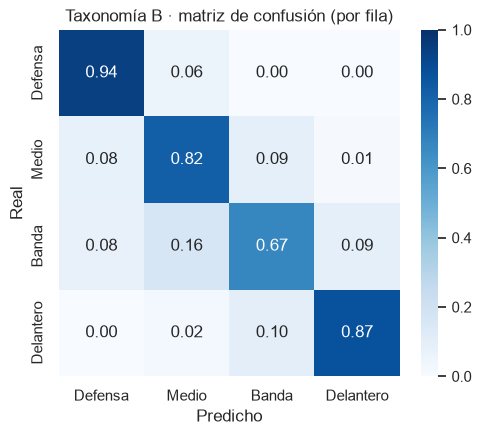

In [5]:
print("Taxonomía B · reporte de clasificación")
print(classification_report(res["B"]["y_te"], res["B"]["pred"], digits=3))

orden_B = ["Defensa", "Medio", "Banda", "Delantero"]
cm = confusion_matrix(res["B"]["y_te"], res["B"]["pred"], labels=orden_B, normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=orden_B, yticklabels=orden_B, ax=ax)
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_title("Taxonomía B · matriz de confusión (por fila)")
plt.show()

In [6]:
def acierto_por_posicion(t):
    r = res[t]
    d = pd.DataFrame({"pos": test_campo["posicion_principal"].to_numpy(), "ok": r["pred"] == r["y_te"]})
    return d.groupby("pos")["ok"].agg(n="size", acierto="mean")

pa, pb = acierto_por_posicion("A"), acierto_por_posicion("B")
tabla = pd.DataFrame({"n": pa["n"], "acierto A": pa["acierto"], "acierto B": pb["acierto"]})
tabla["cambio"] = tabla["acierto B"] - tabla["acierto A"]
display(tabla.sort_values("acierto A").round(3))

,n,acierto A,acierto B,cambio
pos,,,,
LW,83,0.265,0.783,0.518
RW,91,0.330,0.681,0.352
CF,26,0.385,0.308,-0.077
RM,189,0.757,0.624,-0.132
LM,191,0.764,0.660,-0.105
RWB,60,0.767,0.883,0.117
CDM,304,0.786,0.812,0.026
LWB,53,0.849,0.925,0.075
LB,233,0.893,0.931,0.039


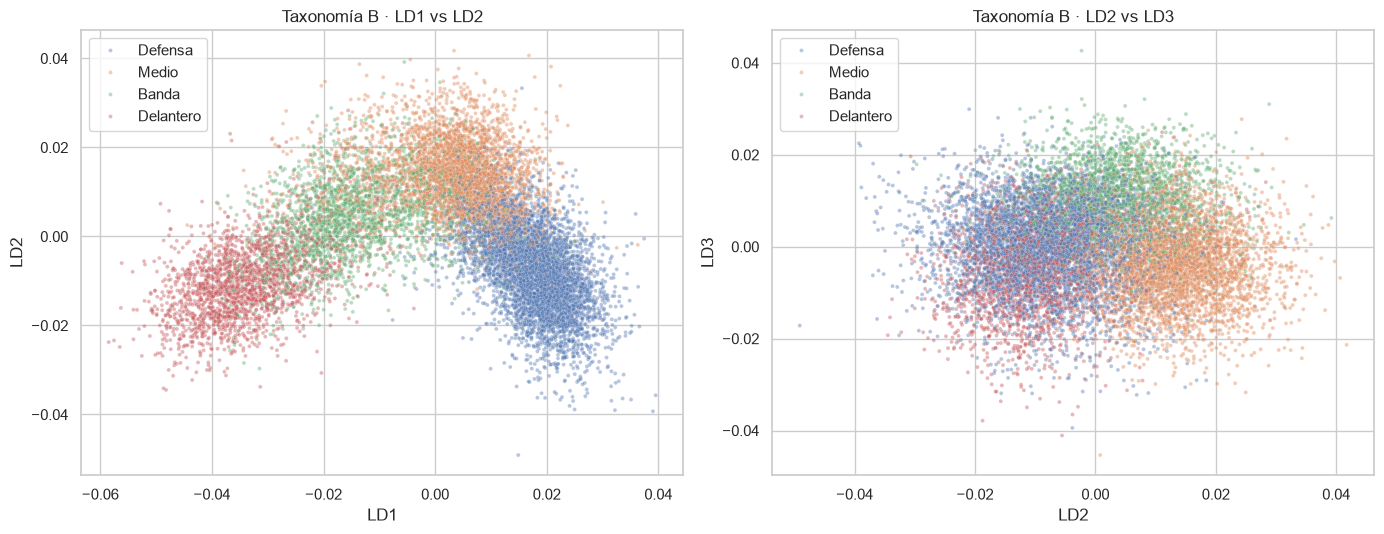

Razón de separación por discriminante: [0.725 0.212 0.063]


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
r = res["B"]
Z = r["modelo"].transformar(X_tr)
for ax, (i, j) in zip(axes, [(0, 1), (1, 2)]):
    sns.scatterplot(x=Z[:, i], y=Z[:, j], hue=r["y_tr"], hue_order=orden_B, s=8, alpha=0.4, ax=ax)
    ax.set_xlabel(f"LD{i + 1}")
    ax.set_ylabel(f"LD{j + 1}")
axes[0].set_title("Taxonomía B · LD1 vs LD2")
axes[1].set_title("Taxonomía B · LD2 vs LD3")
plt.tight_layout()
plt.show()
print("Razón de separación por discriminante:", r["modelo"].fisher.explained_ratio_.round(3))

## 4. Techo de los datos: Random Forest como referencia

Un modelo mucho más flexible, sin proyección, sobre las 37 métricas. Si no supera claramente a Fisher + KNN, el límite lo marcan las etiquetas.

In [8]:
filas = []
for t, r in res.items():
    rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(X_tr, r["y_tr"])
    pred_rf = rf.predict(X_te)
    filas.append({"taxonomía": t, "modelo": "Fisher + KNN",
                  "exactitud": accuracy_score(r["y_te"], r["pred"]), "macro_f1": f1_score(r["y_te"], r["pred"], average="macro")})
    filas.append({"taxonomía": t, "modelo": "Random Forest",
                  "exactitud": accuracy_score(r["y_te"], pred_rf), "macro_f1": f1_score(r["y_te"], pred_rf, average="macro")})
display(pd.DataFrame(filas).round(4))

,taxonomía,modelo,exactitud,macro_f1
0,A,Fisher + KNN,0.8605,0.8524
1,A,Random Forest,0.8822,0.8737
2,B,Fisher + KNN,0.8470,0.8276
3,B,Random Forest,0.8715,0.8538


## 5. Salida probabilística

Las proporciones de votos de KNN se tratan como probabilidades. Se evalúa:

- **Top-1 y top-2:** si la posición real es la más probable, o está entre las dos más probables.
- **Log-loss** (con suavizado de Laplace para evitar probabilidades exactamente 0), frente a una referencia que solo usa las frecuencias de clase.
- **Calibración:** cuando el modelo dice "60%", ¿ocurre el 60% de las veces?

In [9]:
def metricas_proba(r):
    proba, clases, k = r["proba"], r["modelo"].classes_, r["k"]
    y_idx = np.searchsorted(clases, r["y_te"])
    n, C = proba.shape

    orden = argsort_estable(-proba, axis=1)
    top1 = (orden[:, 0] == y_idx).mean()
    top2 = (orden[:, :2] == y_idx[:, None]).any(axis=1).mean()

    suav = (proba * k + 0.5) / (k + 0.5 * C)
    logloss = -np.log(suav[np.arange(n), y_idx]).mean()

    prior = np.array([(r["y_tr"] == c).mean() for c in clases])
    logloss_prior = -np.log(prior[y_idx]).mean()
    return {"top-1": top1, "top-2": top2, "log-loss": logloss, "log-loss (solo frecuencias)": logloss_prior}

display(pd.DataFrame({t: metricas_proba(r) for t, r in res.items()}).T.round(4))

,top-1,top-2,log-loss,log-loss (solo frecuencias)
A,0.8605,0.9926,0.3392,1.0621
B,0.8470,0.9666,0.4205,1.3205


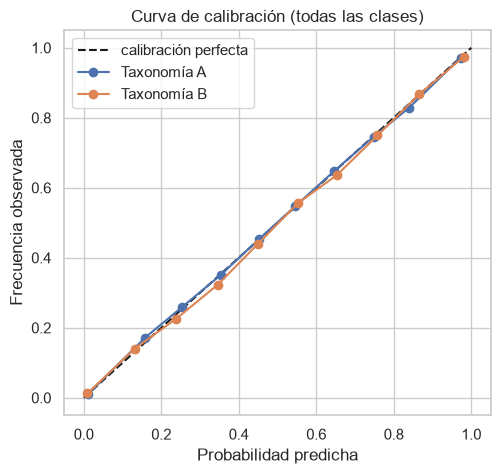

In [10]:
def curva_calibracion(r, bins=10):
    proba, clases = r["proba"], r["modelo"].classes_
    y_idx = np.searchsorted(clases, r["y_te"])
    p = proba.ravel()
    obs = (np.arange(len(clases))[None, :] == y_idx[:, None]).ravel().astype(float)
    cat = np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1])
    return (pd.DataFrame({"p": p, "obs": obs, "bin": cat})
              .groupby("bin").agg(p_media=("p", "mean"), frecuencia=("obs", "mean"), n=("obs", "size")))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "k--", label="calibración perfecta")
for t, r in res.items():
    c = curva_calibracion(r)
    ax.plot(c["p_media"], c["frecuencia"], marker="o", label=f"Taxonomía {t}")
ax.set_xlabel("Probabilidad predicha")
ax.set_ylabel("Frecuencia observada")
ax.set_title("Curva de calibración (todas las clases)")
ax.legend()
plt.show()

## 6. Evaluación con posiciones secundarias

El dataset lista todas las posiciones de cada jugador. Se define el acierto **flexible**: la clase predicha coincide con la macro-clase de *cualquiera* de sus posiciones. Se compara con el acierto **estricto**, que solo mira la posición principal.

In [11]:
def macroclases(texto, mapa):
    return {mapa[p.strip()] for p in str(texto).split(",") if p.strip() in mapa}

filas = []
for t, r in res.items():
    S = test_campo["player_positions"].apply(lambda s: macroclases(s, MAPAS[t]))
    multi = S.apply(len).to_numpy() > 1
    estricto = (r["pred"] == r["y_te"])
    flexible = np.array([p in s for p, s in zip(r["pred"], S)])

    filas.append({"taxonomía": t, "grupo": "todos", "n": len(S),
                  "estricto": estricto.mean(), "flexible": flexible.mean()})
    filas.append({"taxonomía": t, "grupo": "con varias macro-clases", "n": int(multi.sum()),
                  "estricto": estricto[multi].mean(), "flexible": flexible[multi].mean()})
display(pd.DataFrame(filas).round(4))

,taxonomía,grupo,n,estricto,flexible
0,A,todos,3261,0.8605,0.9255
1,A,con varias macro-clases,758,0.7045,0.9842
2,B,todos,3261,0.8470,0.9197
3,B,con varias macro-clases,916,0.6725,0.9312


## 7. ¿Se pueden distinguir las posiciones espejo?

Para cada par izquierda/derecha se entrena un clasificador binario (regresión logística con validación cruzada). Si las métricas no contienen información del lado del campo, la exactitud debería ser igual a la línea base de la clase mayoritaria.

In [12]:
pares = [("LB", "RB"), ("LWB", "RWB"), ("LM", "RM"), ("LW", "RW")]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas = []

for a, b in pares:
    m = train_campo["posicion_principal"].isin([a, b])
    X = train_campo.loc[m, metricas_campo]
    y = (train_campo.loc[m, "posicion_principal"] == a).to_numpy()
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    acc = cross_val_score(modelo, X, y, cv=cv5, scoring="accuracy").mean()
    filas.append({"par": f"{a} vs {b}", "n": int(m.sum()),
                  "exactitud (CV)": acc, "línea base (mayoría)": max(y.mean(), 1 - y.mean())})

display(pd.DataFrame(filas).round(3))

,par,n,exactitud (CV),línea base (mayoría)
0,LB vs RB,1878,0.587,0.505
1,LWB vs RWB,453,0.492,0.532
2,LM vs RM,1521,0.513,0.504
3,LW vs RW,696,0.494,0.522


## Conclusiones

- **Efecto de la taxonomía B:** mejora mucho LW (0.29 → 0.78) y RW (0.33 → 0.68), pero empeora CAM (0.90 → 0.59), RM y LM (≈ −0.12), y CF, ST y CM levemente. La exactitud global baja (0.846 vs 0.862) y el macro-F1 también (0.827 vs 0.854), aunque no son estrictamente comparables.
- **Nuevas fronteras de error:** Banda es la clase más débil (recall 0.664) y se confunde con Medio (17%), Defensa (8%) y Delantero (9%). En Fisher, Banda aparece como zona de transición entre Medio y Delantero, no como grupo aparte.
- **Random Forest vs. Fisher + KNN:** el Random Forest gana 2 a 2.7 puntos (0.882 vs 0.862 en A; 0.872 vs 0.846 en B). El techo ronda el 88%; el resto es ambigüedad de etiquetas.
- **Calidad de las probabilidades:** curva de calibración casi sobre la diagonal en A y B. Log-loss 0.338 (A) y 0.421 (B), frente a 1.062 y 1.321 con solo frecuencias. Top-2: 0.993 (A) y 0.967 (B).
- **Acierto flexible vs. estricto:** en jugadores con varias macro-clases, 0.706 → 0.984 (A) y 0.667 → 0.930 (B). Con una sola macro-clase el acierto ronda el 91%.
- **Pares espejo:** LB/RB 0.587 (base 0.505), señal débil; LWB/RWB 0.492, LM/RM 0.513 y LW/RW 0.494 quedan en la línea base. Se fusionan en el Nivel 2.
- **Decisión de taxonomía:** no hay un ganador claro en este Nivel 1. Se evaluará A frente a B con el ensamble completo, usando enrutamiento suave y métricas top-k sobre la posición específica.